# Tuần 9 — Người 1: Data Pipeline & Classical Baselines

Notebook độc lập, chuyển từ `01_Data_Pipeline_Classical_Baseline.py`.
**File `.py` gốc được giữ nguyên.** Không cần upload script để chạy notebook.

Chạy từ trên xuống bằng **Runtime → Run all** trên Google Colab (CPU là đủ).
Mỗi bước có cell riêng để lưu log, bảng và biểu đồ trong notebook.
Sau khi chạy, lưu notebook để giữ các output của cell.

1. Upload hai CSV vào `/content`, hoặc sửa đường dẫn ở cell cấu hình.
   Nếu dùng Google Drive, bật `MOUNT_GOOGLE_DRIVE` rồi đặt đường dẫn CSV.
2. Chạy pipeline: audit dữ liệu → split theo `essay_id` (80/20, seed 42)
   → chẩn đoán LR → benchmark hai bộ đặc trưng A/B → xuất kết quả.
3. Bảng benchmark và dự đoán của mô hình tốt nhất **tạm thời** được lưu sau
   mỗi mô hình. Cell cuối tạo ZIP chứa nguyên thư mục `outputs/` để tải về.
   CSV đã lưu vẫn còn khi cell sau lỗi; nếu runtime bị xóa, cần tải kết quả
   trước đó hoặc chạy lại. Notebook không checkpoint mô hình đang huấn luyện.

**Giữ nguyên toàn bộ tên file và cột CSV của script gốc**, gồm:
- `outputs/split_assignments.csv`
- `outputs/dataset_split_summary_table.csv`
- `outputs/lr_diagnostic_ablation_summary.csv`
- `outputs/classical_baselines_summary.csv`
- `outputs/strongest_baseline_predictions.csv`
- `outputs/confusion_matrix_strongest_baseline.csv`

Hai PNG cũng giữ tên gốc. Thư mục `outputs/` nằm trong thư mục làm việc
của runtime (`/content/outputs` trên Colab), độc lập với nơi đặt dữ liệu.
Chạy lại sẽ cập nhật các file kết quả cùng tên trong thư mục này.

## 0.1. Chuẩn bị thư viện
Colab đã có NumPy, pandas và SciPy. Cell này bảo đảm API OneHotEncoder,
boxplot phù hợp và cài LightGBM cho đủ benchmark. Chạy trước các cell import.

In [1]:
%pip install -q "scikit-learn>=1.2" "matplotlib>=3.9" lightgbm

## 0.2. Import thư viện

In [2]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# Scikit-Learn components
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

# Optional LightGBM import with automatic fallback / installer
try:
    import lightgbm as lgb
    from lightgbm import LGBMClassifier
    HAS_LIGHTGBM = True
except ImportError:
    print("[INFO] LightGBM not found. Attempting automatic installation via pip...")
    try:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "lightgbm"])
        import lightgbm as lgb
        from lightgbm import LGBMClassifier
        HAS_LIGHTGBM = True
        print("[SUCCESS] LightGBM installed and imported successfully.")
    except Exception as _e:
        print(f"[WARNING] LightGBM installation failed: {_e}. LightGBM baseline will be skipped.")
        HAS_LIGHTGBM = False

# Suppress annoying convergence warnings when running deliberate diagnostics
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## 0.3. Đường dẫn dataset và thư mục kết quả
Để `None` để tự tìm hai file có tên chuẩn. Có thể nhập đường dẫn riêng cho
train và test; không cần đổi tên dataset. Ví dụ:
`TRAIN_CSV_PATH = "/content/drive/MyDrive/MLA Dataset/train.csv"`.

Trên máy dự án, tự nhận `data/raw/train.csv` và CSV test trong
`data/raw/official_test/`. Chỉ sửa đường dẫn đầu vào, giữ tên file output.

In [3]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
IN_COLAB = "google.colab" in sys.modules

MOUNT_GOOGLE_DRIVE = False
TRAIN_CSV_PATH = None  # Hoặc đường dẫn đầy đủ tới CSV train.
TEST_CSV_PATH = None   # Hoặc đường dẫn đầy đủ tới CSV test.

if MOUNT_GOOGLE_DRIVE:
    if not IN_COLAB:
        raise RuntimeError("Google Drive mount chỉ dùng trên Google Colab.")
    from google.colab import drive
    drive.mount("/content/drive")

CANDIDATE_DIRS = [
    Path.cwd(), Path.cwd().parent, Path("/content"),
    Path("/content/drive/MyDrive/Colab Notebooks/MLA/dataset"),
    Path("/content/drive/MyDrive/MLA Dataset"),
    Path("/content/drive/MyDrive/MLA"),
    Path(r"C:\Users\Admin\Desktop\MLA Dataset"),
]
train_candidates = [p / "persuade_corpus_2.0_train.csv" for p in CANDIDATE_DIRS]
test_candidates = [p / "persuade_corpus_2.0_test.csv" for p in CANDIDATE_DIRS]
for root in [Path.cwd(), Path.cwd().parent]:
    train_candidates.append(root / "data/raw/train.csv")
    test_candidates.append(root / "data/raw/official_test/persuade_corpus_2.0_test.csv")

TRAIN_CSV_PATH = (Path(TRAIN_CSV_PATH).expanduser() if TRAIN_CSV_PATH is not None
                  else next((p for p in train_candidates if p.is_file()), None))
TEST_CSV_PATH = (Path(TEST_CSV_PATH).expanduser() if TEST_CSV_PATH is not None
                 else next((p for p in test_candidates if p.is_file()), None))
for role, path in [("train", TRAIN_CSV_PATH), ("test", TEST_CSV_PATH)]:
    if path is None or not path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy CSV {role}. Upload vào /content hoặc sửa "
            f"{role.upper()}_CSV_PATH ở đầu cell này rồi chạy lại."
        )

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Environment: {'Google Colab' if IN_COLAB else 'Local'} | Seed: {RANDOM_SEED}")
print(f"Train: {TRAIN_CSV_PATH.resolve()}")
print(f"Test:  {TEST_CSV_PATH.resolve()}")
print(f"Outputs: {OUTPUT_DIR.resolve()}")

Environment: Google Colab | Seed: 42
Train: /content/week9_person1_20261014/persuade_corpus_2.0_train.csv
Test:  /content/week9_person1_20261014/persuade_corpus_2.0_test.csv
Outputs: /content/week9_person1_20261014/outputs


## 1.1. Nạp dữ liệu và audit schema

In [4]:
print("\n" + "=" * 80)
print("SECTION 1.1:LOADING RAW DATASETS & AUDITING SCHEMA")
print("=" * 80)

t0 = time.time()
df_train_raw = pd.read_csv(TRAIN_CSV_PATH, low_memory=False)
df_test_raw = pd.read_csv(TEST_CSV_PATH, low_memory=False)
load_elapsed = time.time() - t0

print(f"[OK] Raw datasets loaded in {load_elapsed:.2f} seconds.")
print(f" - Train raw shape: {df_train_raw.shape[0]:,} rows | {df_train_raw.shape[1]} columns")
print(f" - Test raw shape:  {df_test_raw.shape[0]:,} rows | {df_test_raw.shape[1]} columns")

# Display column types and missing values
schema_summary = pd.DataFrame({
    "Train Dtype": df_train_raw.dtypes,
    "Train Nulls": df_train_raw.isnull().sum(),
    "Train Null %": (df_train_raw.isnull().mean() * 100).round(2),
    "Test Dtype": df_test_raw.dtypes,
    "Test Nulls": df_test_raw.isnull().sum(),
    "Test Null %": (df_test_raw.isnull().mean() * 100).round(2),
})
print("\n--- SCHEMA & NULL VALUE SUMMARY ---")
print(schema_summary.to_string())


SECTION 1.1:LOADING RAW DATASETS & AUDITING SCHEMA


[OK] Raw datasets loaded in 14.35 seconds.
 - Train raw shape: 173,266 rows | 27 columns
 - Test raw shape:  112,117 rows | 27 columns



--- SCHEMA & NULL VALUE SUMMARY ---
                           Train Dtype  Train Nulls  Train Null % Test Dtype  Test Nulls  Test Null %
essay_id                        object            0          0.00     object           0         0.00
essay_id_comp                   object            0          0.00     object           0         0.00
competition_set                 object            0          0.00     object           0         0.00
full_text                       object            0          0.00     object           0         0.00
holistic_essay_score             int64            0          0.00      int64           0         0.00
discourse_id                   float64            0          0.00    float64           0         0.00
discourse_start                  int64            0          0.00      int64           0         0.00
discourse_end                    int64            0          0.00      int64           0         0.00
discourse_text                  object       

In [5]:
REQUIRED_COLUMNS = {
    "essay_id", "discourse_id", "discourse_text", "discourse_type",
    "discourse_effectiveness", "discourse_start", "essay_word_count",
}
for name, frame in [("train", df_train_raw), ("test", df_test_raw)]:
    missing = REQUIRED_COLUMNS - set(frame.columns)
    if missing:
        raise ValueError(f"CSV {name} thiếu cột: {sorted(missing)}")
    annotated = frame.dropna(subset=["discourse_effectiveness"])
    if annotated.empty:
        raise ValueError(f"CSV {name} không có mẫu được gán nhãn.")
    if annotated[["essay_id", "discourse_id"]].isna().any().any():
        raise ValueError(f"CSV {name} có ID rỗng trong các mẫu được gán nhãn.")
    unknown = set(annotated["discourse_effectiveness"]) - {"Ineffective", "Adequate", "Effective"}
    if unknown:
        raise ValueError(f"CSV {name} có nhãn không hợp lệ: {sorted(unknown)}")
print("[OK] Schema, ID và nhãn đầu vào hợp lệ.")

[OK] Schema, ID và nhãn đầu vào hợp lệ.


## 1.2. Phân bố nhãn và loại lập luận

In [6]:
print("\n" + "=" * 80)
print("SECTION 1.2:LABEL & DISCOURSE TYPE DISTRIBUTIONS")
print("=" * 80)

TARGET_COL = "discourse_effectiveness"
ORDERED_LABELS = ["Ineffective", "Adequate", "Effective"]

# 1. Label distribution in raw train
train_label_counts = df_train_raw[TARGET_COL].value_counts(dropna=False)
train_label_pcts = (df_train_raw[TARGET_COL].value_counts(normalize=True, dropna=False) * 100).round(2)
train_label_df = pd.DataFrame({"Count": train_label_counts, "Percentage (%)": train_label_pcts})
train_label_df.index = train_label_df.index.fillna("Unannotated / NaN")

print("\n--- TRAIN SET: DISCOURSE EFFECTIVENESS DISTRIBUTION (RAW) ---")
print(train_label_df.to_string())

# 2. Label distribution in raw test
test_label_counts = df_test_raw[TARGET_COL].value_counts(dropna=False)
test_label_pcts = (df_test_raw[TARGET_COL].value_counts(normalize=True, dropna=False) * 100).round(2)
test_label_df = pd.DataFrame({"Count": test_label_counts, "Percentage (%)": test_label_pcts})
test_label_df.index = test_label_df.index.fillna("Unannotated / NaN")

print("\n--- TEST SET: DISCOURSE EFFECTIVENESS DISTRIBUTION (RAW) ---")
print(test_label_df.to_string())

# 3. Unique essay counts
n_train_essays_raw = df_train_raw["essay_id"].nunique()
n_test_essays_raw = df_test_raw["essay_id"].nunique()
print(f"\n[*] Unique Essay IDs: Train Raw = {n_train_essays_raw:,} | Test Raw = {n_test_essays_raw:,}")

# 4. Discourse type distribution
dtype_train = df_train_raw["discourse_type"].value_counts(dropna=False)
dtype_train_pct = (df_train_raw["discourse_type"].value_counts(normalize=True, dropna=False) * 100).round(2)
dtype_test = df_test_raw["discourse_type"].value_counts(dropna=False)
dtype_test_pct = (df_test_raw["discourse_type"].value_counts(normalize=True, dropna=False) * 100).round(2)

dtype_summary = pd.DataFrame({
    "Train Count": dtype_train,
    "Train %": dtype_train_pct,
    "Test Count": dtype_test,
    "Test %": dtype_test_pct,
}).fillna(0)
print("\n--- DISCOURSE TYPE DISTRIBUTION ---")
print(dtype_summary.to_string())

# Clarification on annotated units
df_train_annotated = df_train_raw.dropna(subset=[TARGET_COL]).copy().reset_index(drop=True)
df_test_annotated = df_test_raw.dropna(subset=[TARGET_COL]).copy().reset_index(drop=True)

print(f"\n[NOTE ON ANNOTATED UNITS]")
print(f"Supervised discourse effectiveness classification evaluates annotated discourse elements:")
print(f" - Train Annotated Units: {len(df_train_annotated):,} / {len(df_train_raw):,} "
      f"({len(df_train_raw) - len(df_train_annotated):,} unannotated filtered)")
print(f" - Test Annotated Units:  {len(df_test_annotated):,} / {len(df_test_raw):,} "
      f"({len(df_test_raw) - len(df_test_annotated):,} unannotated filtered)")


SECTION 1.2:LABEL & DISCOURSE TYPE DISTRIBUTIONS

--- TRAIN SET: DISCOURSE EFFECTIVENESS DISTRIBUTION (RAW) ---
                          Count  Percentage (%)
discourse_effectiveness                        
Adequate                 113244           65.36
Unannotated / NaN         28977           16.72
Effective                 24583           14.19
Ineffective                6462            3.73

--- TEST SET: DISCOURSE EFFECTIVENESS DISTRIBUTION (RAW) ---
                         Count  Percentage (%)
discourse_effectiveness                       
Adequate                 75363           67.22
Unannotated / NaN        18440           16.45
Effective                14089           12.57
Ineffective               4225            3.77

[*] Unique Essay IDs: Train Raw = 15,593 | Test Raw = 10,402

--- DISCOURSE TYPE DISTRIBUTION ---
                      Train Count  Train %  Test Count  Test %
discourse_type                                                
Claim                       50


[NOTE ON ANNOTATED UNITS]
Supervised discourse effectiveness classification evaluates annotated discourse elements:
 - Train Annotated Units: 144,289 / 173,266 (28,977 unannotated filtered)
 - Test Annotated Units:  93,677 / 112,117 (18,440 unannotated filtered)


## 1.3. Split theo bài văn và lưu mapping
Lưu ngay `outputs/split_assignments.csv` và
`outputs/dataset_split_summary_table.csv`. Số lượng mẫu được tính từ dữ liệu
đang nạp; không ép bằng số lượng của các protocol báo cáo trước đó.

In [7]:
print("\n" + "=" * 80)
print("SECTION 1.3:LEAK-FREE GROUPSHUFFLESPLIT (80% TRAIN / 20% VAL BY ESSAY_ID)")
print("=" * 80)

# Group-aware split to ensure zero essay leakage
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_SEED)
train_indices, val_indices = next(gss.split(df_train_annotated, groups=df_train_annotated["essay_id"]))

df_train_split = df_train_annotated.iloc[train_indices].copy().reset_index(drop=True)
df_val_split = df_train_annotated.iloc[val_indices].copy().reset_index(drop=True)

train_essays = set(df_train_split["essay_id"].unique())
val_essays = set(df_val_split["essay_id"].unique())
overlap_essays = train_essays.intersection(val_essays)

# VERIFICATION ASSERTION
assert len(overlap_essays) == 0, f"FATAL ERROR: Found {len(overlap_essays)} overlapping essays between Train and Val!"
print(f"[VERIFICATION PASSED] Zero essay leakage confirmed!")
print(f" - Train Essays: {len(train_essays):,}")
print(f" - Val Essays:   {len(val_essays):,}")
print(f" - Overlap:      {len(overlap_essays)} essays")

# Save split assignments for reproducibility and cross-model alignment
all_train_essays = df_train_raw["essay_id"].drop_duplicates().to_frame()
all_train_essays["split"] = np.where(all_train_essays["essay_id"].isin(val_essays), "val", "train")

split_csv_path = OUTPUT_DIR / "split_assignments.csv"
all_train_essays.to_csv(split_csv_path, index=False)
print(f"[SAVED] Split assignments exported to: {split_csv_path.resolve()}")

# Comprehensive Data Summary Table
summary_records = [
    {
        "Cohort": "Train Raw (Full)",
        "Essays": df_train_raw["essay_id"].nunique(),
        "Discourse Units": len(df_train_raw),
        "Ineffective (%)": f"{(df_train_raw[TARGET_COL] == 'Ineffective').mean()*100:.2f}%",
        "Adequate (%)": f"{(df_train_raw[TARGET_COL] == 'Adequate').mean()*100:.2f}%",
        "Effective (%)": f"{(df_train_raw[TARGET_COL] == 'Effective').mean()*100:.2f}%",
        "Unannotated (%)": f"{df_train_raw[TARGET_COL].isna().mean()*100:.2f}%",
    },
    {
        "Cohort": "Train Annotated (Total)",
        "Essays": df_train_annotated["essay_id"].nunique(),
        "Discourse Units": len(df_train_annotated),
        "Ineffective (%)": f"{(df_train_annotated[TARGET_COL] == 'Ineffective').mean()*100:.2f}%",
        "Adequate (%)": f"{(df_train_annotated[TARGET_COL] == 'Adequate').mean()*100:.2f}%",
        "Effective (%)": f"{(df_train_annotated[TARGET_COL] == 'Effective').mean()*100:.2f}%",
        "Unannotated (%)": "0.00%",
    },
    {
        "Cohort": "Train Split (80% Fit)",
        "Essays": len(train_essays),
        "Discourse Units": len(df_train_split),
        "Ineffective (%)": f"{(df_train_split[TARGET_COL] == 'Ineffective').mean()*100:.2f}%",
        "Adequate (%)": f"{(df_train_split[TARGET_COL] == 'Adequate').mean()*100:.2f}%",
        "Effective (%)": f"{(df_train_split[TARGET_COL] == 'Effective').mean()*100:.2f}%",
        "Unannotated (%)": "0.00%",
    },
    {
        "Cohort": "Validation Split (20% Val)",
        "Essays": len(val_essays),
        "Discourse Units": len(df_val_split),
        "Ineffective (%)": f"{(df_val_split[TARGET_COL] == 'Ineffective').mean()*100:.2f}%",
        "Adequate (%)": f"{(df_val_split[TARGET_COL] == 'Adequate').mean()*100:.2f}%",
        "Effective (%)": f"{(df_val_split[TARGET_COL] == 'Effective').mean()*100:.2f}%",
        "Unannotated (%)": "0.00%",
    },
    {
        "Cohort": "Test Annotated (Holdout)",
        "Essays": df_test_annotated["essay_id"].nunique(),
        "Discourse Units": len(df_test_annotated),
        "Ineffective (%)": f"{(df_test_annotated[TARGET_COL] == 'Ineffective').mean()*100:.2f}%",
        "Adequate (%)": f"{(df_test_annotated[TARGET_COL] == 'Adequate').mean()*100:.2f}%",
        "Effective (%)": f"{(df_test_annotated[TARGET_COL] == 'Effective').mean()*100:.2f}%",
        "Unannotated (%)": "0.00%",
    },
]

df_summary_table = pd.DataFrame(summary_records)
print("\n" + "=" * 80)
print("COMPREHENSIVE DATA & SPLIT SUMMARY TABLE")
print("=" * 80)
print(df_summary_table.to_string(index=False))

# Export summary table to CSV
summary_table_path = OUTPUT_DIR / "dataset_split_summary_table.csv"
df_summary_table.to_csv(summary_table_path, index=False)
print(f"[SAVED] Data summary table exported to: {summary_table_path.resolve()}")


SECTION 1.3:LEAK-FREE GROUPSHUFFLESPLIT (80% TRAIN / 20% VAL BY ESSAY_ID)


[VERIFICATION PASSED] Zero essay leakage confirmed!
 - Train Essays: 12,474
 - Val Essays:   3,119
 - Overlap:      0 essays
[SAVED] Split assignments exported to: /content/week9_person1_20261014/outputs/split_assignments.csv



COMPREHENSIVE DATA & SPLIT SUMMARY TABLE
                    Cohort  Essays  Discourse Units Ineffective (%) Adequate (%) Effective (%) Unannotated (%)
          Train Raw (Full)   15593           173266           3.73%       65.36%        14.19%          16.72%
   Train Annotated (Total)   15593           144289           4.48%       78.48%        17.04%           0.00%
     Train Split (80% Fit)   12474           115187           4.46%       78.44%        17.11%           0.00%
Validation Split (20% Val)    3119            29102           4.56%       78.68%        16.76%           0.00%
  Test Annotated (Holdout)   10402            93677           4.51%       80.45%        15.04%           0.00%
[SAVED] Data summary table exported to: /content/week9_person1_20261014/outputs/dataset_split_summary_table.csv


## 1.4. EDA và lưu biểu đồ phân bố độ dài


SECTION 1.4:EXPLORATORY DATA ANALYSIS (EDA)



--- CROSSTAB: DISCOURSE TYPE VS EFFECTIVENESS (RAW COUNTS) ---
discourse_effectiveness  Adequate  Effective  Ineffective     All
discourse_type                                                   
Claim                       40561       8172         1475   50208
Concluding Statement        10407       2516          581   13504
Counterclaim                 4771        841          205    5817
Evidence                    34063       8483         3156   45702
Lead                         6949       1990          364    9303
Position                    13087       1861          470   15418
Rebuttal                     3406        720          211    4337
All                        113244      24583         6462  144289

--- CROSSTAB: DISCOURSE TYPE VS EFFECTIVENESS (ROW PERCENTAGES %) ---
discourse_effectiveness  Adequate  Effective  Ineffective
discourse_type                                           
Claim                       80.79      16.28         2.94
Concluding Statement        77.

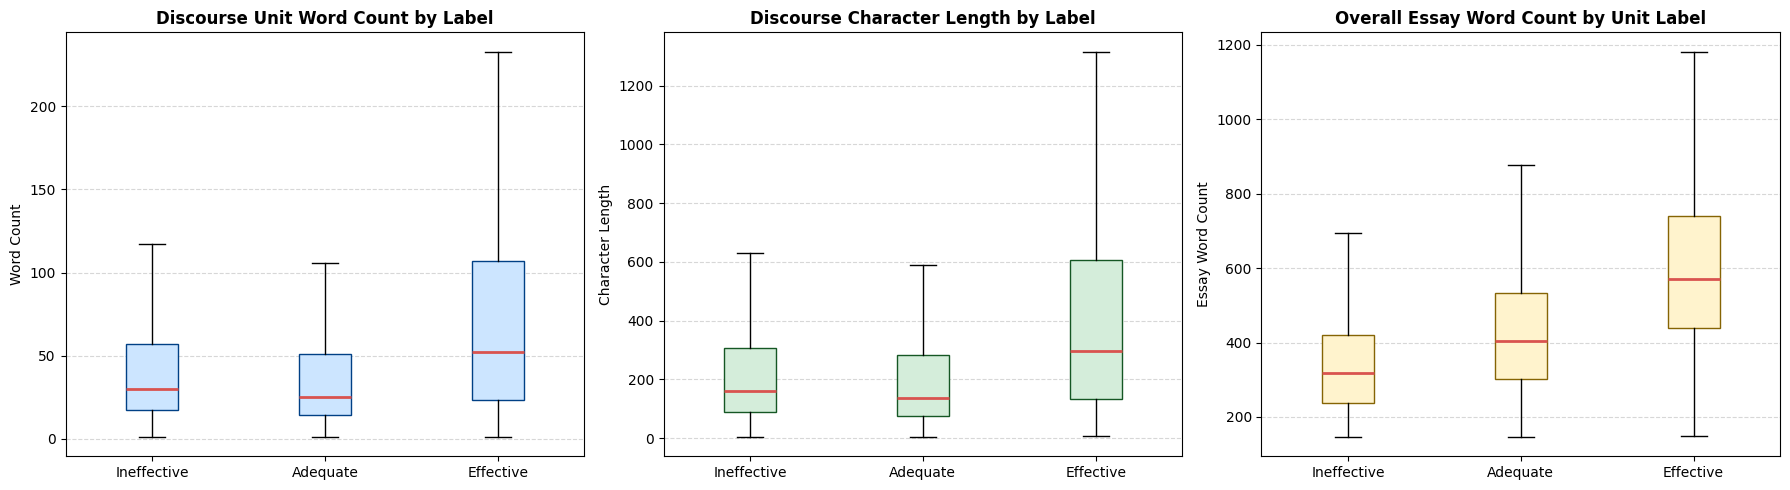

[SAVED] EDA distributions figure saved to: /content/week9_person1_20261014/outputs/eda_length_distributions_by_label.png


In [8]:
print("\n" + "=" * 80)
print("SECTION 1.4:EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 80)

# Precompute textual length metrics safely
for df_ref in [df_train_annotated, df_train_split, df_val_split]:
    df_ref["discourse_text"] = df_ref["discourse_text"].fillna("")
    df_ref["discourse_char_len"] = df_ref["discourse_text"].str.len()
    df_ref["discourse_word_count"] = df_ref["discourse_text"].str.split().str.len().fillna(0)

# 1. Crosstab: Target Label vs Discourse Type
ct_counts = pd.crosstab(df_train_annotated["discourse_type"], df_train_annotated[TARGET_COL], margins=True)
ct_pct_row = (pd.crosstab(df_train_annotated["discourse_type"], df_train_annotated[TARGET_COL], normalize="index") * 100).round(2)

print("\n--- CROSSTAB: DISCOURSE TYPE VS EFFECTIVENESS (RAW COUNTS) ---")
print(ct_counts.to_string())

print("\n--- CROSSTAB: DISCOURSE TYPE VS EFFECTIVENESS (ROW PERCENTAGES %) ---")
print(ct_pct_row.to_string())

# 2. Textual length and essay word count statistics by label
len_stats = df_train_annotated.groupby(TARGET_COL).agg({
    "discourse_char_len": ["mean", "std", "median", "min", "max"],
    "discourse_word_count": ["mean", "std", "median", "min", "max"],
    "essay_word_count": ["mean", "std", "median", "min", "max"]
}).round(2)

print("\n--- TEXTUAL LENGTH STATISTICS BY EFFECTIVENESS LABEL ---")
print(len_stats.to_string())

# 3. Generate and save EDA figures
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Discourse Word Count Boxplot by Label
labels_order = ["Ineffective", "Adequate", "Effective"]
word_count_data = [df_train_annotated[df_train_annotated[TARGET_COL] == lab]["discourse_word_count"].values for lab in labels_order]
axes[0].boxplot(word_count_data, tick_labels=labels_order, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="#cce5ff", color="#004085"),
                medianprops=dict(color="#d9534f", linewidth=2))
axes[0].set_title("Discourse Unit Word Count by Label", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Word Count")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot B: Discourse Character Length Boxplot by Label
char_len_data = [df_train_annotated[df_train_annotated[TARGET_COL] == lab]["discourse_char_len"].values for lab in labels_order]
axes[1].boxplot(char_len_data, tick_labels=labels_order, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="#d4edda", color="#155724"),
                medianprops=dict(color="#d9534f", linewidth=2))
axes[1].set_title("Discourse Character Length by Label", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Character Length")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Plot C: Essay Total Word Count Boxplot by Label
essay_wc_data = [df_train_annotated[df_train_annotated[TARGET_COL] == lab]["essay_word_count"].dropna().values for lab in labels_order]
axes[2].boxplot(essay_wc_data, tick_labels=labels_order, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="#fff3cd", color="#856404"),
                medianprops=dict(color="#d9534f", linewidth=2))
axes[2].set_title("Overall Essay Word Count by Unit Label", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Essay Word Count")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
eda_fig_path = OUTPUT_DIR / "eda_length_distributions_by_label.png"
plt.savefig(eda_fig_path, dpi=300)
plt.show()
plt.close()
print(f"[SAVED] EDA distributions figure saved to: {eda_fig_path.resolve()}")

## 2.1. Tái hiện logic LR sai và so với LR mặc định
Giữ logic sai **có chủ đích** để chẩn đoán lỗi thứ tự nhãn. Con số 6.13%
là kết quả từng được báo cáo, không phải kết quả được bảo đảm trên split này.
Đọc accuracy, recall và phân bố dự đoán do cell thực sự tính được.

In [9]:
print("\n" + "=" * 80)
print("SECTION 2.1:REPRODUCING THE REPORTED LOGISTIC REGRESSION ANOMALY")
print("=" * 80)

# Build standard TF-IDF representation on discourse_text
TFIDF_MAX_FEATURES = 15000
tfidf_diag = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, min_df=2, ngram_range=(1, 2))

X_train_text_diag = tfidf_diag.fit_transform(df_train_split["discourse_text"])
X_val_text_diag = tfidf_diag.transform(df_val_split["discourse_text"])
y_train_diag = df_train_split[TARGET_COL].values
y_val_diag = df_val_split[TARGET_COL].values

print(f"[OK] TF-IDF matrix built: Train = {X_train_text_diag.shape} | Val = {X_val_text_diag.shape}")

# Model 1: Default unweighted Logistic Regression (max_iter=100)
lr_default = LogisticRegression(max_iter=100, random_state=RANDOM_SEED)
lr_default.fit(X_train_text_diag, y_train_diag)
preds_default = lr_default.predict(X_val_text_diag)

acc_def = accuracy_score(y_val_diag, preds_default)
bacc_def = balanced_accuracy_score(y_val_diag, preds_default)
mf1_def = f1_score(y_val_diag, preds_default, average="macro")

print("\n--- MODEL 1: DEFAULT UNWEIGHTED LR (max_iter=100, predict()) ---")
print(f"Accuracy:          {acc_def*100:.2f}%")
print(f"Balanced Accuracy: {bacc_def*100:.2f}%")
print(f"Macro-F1:          {mf1_def:.4f}")
print("Predicted Class Frequencies:")
print(pd.Series(preds_default).value_counts().to_string())
print("\nClassification Report (Default LR):")
print(classification_report(y_val_diag, preds_default, labels=ORDERED_LABELS, target_names=ORDERED_LABELS, digits=4, zero_division=0))

# Model 2: The Flawed 'predict_with_threshold' logic from previous codebase
# Note: In MLA.ipynb, the code defined LABEL_ORDER = ["Ineffective", "Adequate", "Effective"]
# and checked `if prob[LABEL_ORDER.index("Ineffective")] >= 0.20: preds.append("Ineffective")`
# But in scikit-learn, clf.classes_ is ALPHABETICAL: ['Adequate', 'Effective', 'Ineffective']!
# Therefore, index 0 is 'Adequate', NOT 'Ineffective'!
lr_balanced_bug = LogisticRegression(C=2.0, max_iter=500, random_state=RANDOM_SEED, class_weight="balanced")
lr_balanced_bug.fit(X_train_text_diag, y_train_diag)
probs_val_bug = lr_balanced_bug.predict_proba(X_val_text_diag)

FLAWED_LABEL_ORDER = ["Ineffective", "Adequate", "Effective"]
ineffective_flawed_idx = FLAWED_LABEL_ORDER.index("Ineffective")  # evaluates to 0!
INEFFECTIVE_BOOST_THRESHOLD = 0.20

preds_buggy = []
for p_row in probs_val_bug:
    # BUG: p_row[0] is actually P(Adequate), NOT P(Ineffective)!
    if p_row[ineffective_flawed_idx] >= INEFFECTIVE_BOOST_THRESHOLD:
        preds_buggy.append("Ineffective")
    else:
        # BUG: argmax maps into FLAWED_LABEL_ORDER instead of lr_balanced_bug.classes_
        preds_buggy.append(FLAWED_LABEL_ORDER[np.argmax(p_row)])
preds_buggy = np.array(preds_buggy)

acc_bug = accuracy_score(y_val_diag, preds_buggy)
bacc_bug = balanced_accuracy_score(y_val_diag, preds_buggy)
mf1_bug = f1_score(y_val_diag, preds_buggy, average="macro")
rec_ineff_bug = recall_score(y_val_diag == "Ineffective", preds_buggy == "Ineffective", zero_division=0)

print("\n--- MODEL 2: REPRODUCING THE REPORTED '6.13%' ANOMALY (FLAWED THRESHOLD LOGIC) ---")
print(f"Accuracy:            {acc_bug*100:.2f}% (Collapsed to base rate!)")
print(f"Balanced Accuracy:   {bacc_bug*100:.2f}%")
print(f"Macro-F1:            {mf1_bug:.4f}")
print(f"Ineffective Recall:  {rec_ineff_bug*100:.2f}% (Artificially inflated!)")
print("Predicted Class Frequencies:")
print(pd.Series(preds_buggy).value_counts().to_string())
print("\nClassification Report (Flawed Threshold Bug):")
print(classification_report(y_val_diag, preds_buggy, labels=ORDERED_LABELS, target_names=ORDERED_LABELS, digits=4, zero_division=0))


SECTION 2.1:REPRODUCING THE REPORTED LOGISTIC REGRESSION ANOMALY


[OK] TF-IDF matrix built: Train = (115187, 15000) | Val = (29102, 15000)



--- MODEL 1: DEFAULT UNWEIGHTED LR (max_iter=100, predict()) ---
Accuracy:          80.00%
Balanced Accuracy: 40.94%
Macro-F1:          0.4258
Predicted Class Frequencies:
Adequate       27148
Effective       1860
Ineffective       94

Classification Report (Default LR):
              precision    recall  f1-score   support

 Ineffective     0.4681    0.0331    0.0619      1328
    Adequate     0.8148    0.9661    0.8840     22897
   Effective     0.6005    0.2290    0.3316      4877

    accuracy                         0.8000     29102
   macro avg     0.6278    0.4094    0.4258     29102
weighted avg     0.7631    0.8000    0.7539     29102




--- MODEL 2: REPRODUCING THE REPORTED '6.13%' ANOMALY (FLAWED THRESHOLD LOGIC) ---
Accuracy:            8.05% (Collapsed to base rate!)
Balanced Accuracy:   25.85%
Macro-F1:            0.0699
Ineffective Recall:  69.35% (Artificially inflated!)
Predicted Class Frequencies:
Ineffective    24590
Adequate        2722
Effective       1790

Classification Report (Flawed Threshold Bug):


              precision    recall  f1-score   support

 Ineffective     0.0375    0.6935    0.0711      1328
    Adequate     0.4769    0.0567    0.1013     22897
   Effective     0.0693    0.0254    0.0372      4877

    accuracy                         0.0805     29102
   macro avg     0.1945    0.2585    0.0699     29102
weighted avg     0.3885    0.0805    0.0892     29102



## 2.2. Kiểm tra 1 — Thứ tự nhãn thực tế

In [10]:
diag_results = []

# ------------------------------------------------------------------------------
# Check 1: Label Encoding Order Analysis
# ------------------------------------------------------------------------------
print("\n[*] DIAGNOSTIC CHECK 1: Class Order Verification")
actual_classes = list(lr_balanced_bug.classes_)
print(f" - Scikit-Learn `clf.classes_`:  {actual_classes}")
print(f" - Script hardcoded LABEL_ORDER: {FLAWED_LABEL_ORDER}")
print(f" - Index 0 in Scikit-Learn is: '{actual_classes[0]}'")
print(f" - Index 0 in hardcoded list is: '{FLAWED_LABEL_ORDER[0]}'")
print(f" [FINDING] Checking `prob[0] >= 0.20` was checking `P(Adequate) >= 0.20`!")
print(f" - Tỷ lệ mẫu bị ép thành Ineffective: {(probs_val_bug[:, 0] >= 0.20).mean():.2%}")


[*] DIAGNOSTIC CHECK 1: Class Order Verification
 - Scikit-Learn `clf.classes_`:  ['Adequate', 'Effective', 'Ineffective']
 - Script hardcoded LABEL_ORDER: ['Ineffective', 'Adequate', 'Effective']
 - Index 0 in Scikit-Learn is: 'Adequate'
 - Index 0 in hardcoded list is: 'Ineffective'
 [FINDING] Checking `prob[0] >= 0.20` was checking `P(Adequate) >= 0.20`!
 - Tỷ lệ mẫu bị ép thành Ineffective: 84.50%


### Kiểm tra 2 — Hội tụ: 100 và 5.000 vòng lặp
Lưu bảng chẩn đoán sau khi hoàn tất bước này.

In [11]:
# ------------------------------------------------------------------------------
# Check 2: Convergence Analysis (max_iter=100 vs max_iter=5000)
# ------------------------------------------------------------------------------
print("\n[*] DIAGNOSTIC CHECK 2: Convergence Analysis")
with warnings.catch_warnings(record=True) as w_list:
    warnings.simplefilter("always")
    lr_iter100 = LogisticRegression(max_iter=100, solver="lbfgs", random_state=RANDOM_SEED)
    lr_iter100.fit(X_train_text_diag, y_train_diag)
    conv_warn_100 = any(issubclass(warn.category, ConvergenceWarning) for warn in w_list)

with warnings.catch_warnings(record=True) as w_list:
    warnings.simplefilter("always")
    lr_iter5000 = LogisticRegression(max_iter=5000, solver="lbfgs", random_state=RANDOM_SEED)
    lr_iter5000.fit(X_train_text_diag, y_train_diag)
    conv_warn_5000 = any(issubclass(warn.category, ConvergenceWarning) for warn in w_list)

preds_iter100 = lr_iter100.predict(X_val_text_diag)
preds_iter5000 = lr_iter5000.predict(X_val_text_diag)

diag_results.append({
    "Experiment": "Convergence (max_iter=100)",
    "Converged?": "No (Hit 100 limit)" if conv_warn_100 else "Yes",
    "Accuracy (%)": f"{accuracy_score(y_val_diag, preds_iter100)*100:.2f}",
    "Balanced Acc (%)": f"{balanced_accuracy_score(y_val_diag, preds_iter100)*100:.2f}",
    "Macro-F1": f"{f1_score(y_val_diag, preds_iter100, average='macro'):.4f}",
    "Ineffective F1": f"{f1_score(y_val_diag, preds_iter100, labels=['Ineffective'], average=None)[0]:.4f}",
})
diag_results.append({
    "Experiment": "Convergence (max_iter=5000)",
    "Converged?": "No" if conv_warn_5000 else f"Yes ({lr_iter5000.n_iter_[0]} iters)",
    "Accuracy (%)": f"{accuracy_score(y_val_diag, preds_iter5000)*100:.2f}",
    "Balanced Acc (%)": f"{balanced_accuracy_score(y_val_diag, preds_iter5000)*100:.2f}",
    "Macro-F1": f"{f1_score(y_val_diag, preds_iter5000, average='macro'):.4f}",
    "Ineffective F1": f"{f1_score(y_val_diag, preds_iter5000, labels=['Ineffective'], average=None)[0]:.4f}",
})
print(" - Iteration limit test completed.")

pd.DataFrame(diag_results).to_csv(OUTPUT_DIR / "lr_diagnostic_ablation_summary.csv", index=False)
print("[SAVED] outputs/lr_diagnostic_ablation_summary.csv")


[*] DIAGNOSTIC CHECK 2: Convergence Analysis


 - Iteration limit test completed.
[SAVED] outputs/lr_diagnostic_ablation_summary.csv


### Kiểm tra 3 — StandardScaler trên TF-IDF sparse
Lưu bảng chẩn đoán sau khi hoàn tất bước này.

In [12]:
# ------------------------------------------------------------------------------
# Check 3: StandardScaler on Sparse TF-IDF
# ------------------------------------------------------------------------------
print("\n[*] DIAGNOSTIC CHECK 3: StandardScaler on TF-IDF")
# StandardScaler with with_mean=False preserves sparsity
scaler_tfidf = StandardScaler(with_mean=False)
X_train_scaled = scaler_tfidf.fit_transform(X_train_text_diag)
X_val_scaled = scaler_tfidf.transform(X_val_text_diag)

lr_scaled = LogisticRegression(max_iter=1000, solver="lbfgs", random_state=RANDOM_SEED)
lr_scaled.fit(X_train_scaled, y_train_diag)
preds_scaled = lr_scaled.predict(X_val_scaled)

diag_results.append({
    "Experiment": "StandardScaler (with_mean=False)",
    "Converged?": f"{'Yes' if lr_scaled.n_iter_[0] < lr_scaled.max_iter else 'Limit reached'} ({lr_scaled.n_iter_[0]} iters)",
    "Accuracy (%)": f"{accuracy_score(y_val_diag, preds_scaled)*100:.2f}",
    "Balanced Acc (%)": f"{balanced_accuracy_score(y_val_diag, preds_scaled)*100:.2f}",
    "Macro-F1": f"{f1_score(y_val_diag, preds_scaled, average='macro'):.4f}",
    "Ineffective F1": f"{f1_score(y_val_diag, preds_scaled, labels=['Ineffective'], average=None)[0]:.4f}",
})
print(" - StandardScaler evaluation completed.")

pd.DataFrame(diag_results).to_csv(OUTPUT_DIR / "lr_diagnostic_ablation_summary.csv", index=False)
print("[SAVED] outputs/lr_diagnostic_ablation_summary.csv")


[*] DIAGNOSTIC CHECK 3: StandardScaler on TF-IDF


 - StandardScaler evaluation completed.
[SAVED] outputs/lr_diagnostic_ablation_summary.csv


### Kiểm tra 4 — Trọng số lớp balanced
Lưu bảng chẩn đoán sau khi hoàn tất bước này.

In [13]:
# ------------------------------------------------------------------------------
# Check 4: Class Weighting Impact (None vs 'balanced')
# ------------------------------------------------------------------------------
print("\n[*] DIAGNOSTIC CHECK 4: Class Weighting (None vs 'balanced')")
lr_bal = LogisticRegression(max_iter=5000, solver="lbfgs", class_weight="balanced", random_state=RANDOM_SEED)
lr_bal.fit(X_train_text_diag, y_train_diag)
preds_bal = lr_bal.predict(X_val_text_diag)

diag_results.append({
    "Experiment": "Class Weight: Balanced (Correct Predict)",
    "Converged?": f"{'Yes' if lr_bal.n_iter_[0] < lr_bal.max_iter else 'Limit reached'} ({lr_bal.n_iter_[0]} iters)",
    "Accuracy (%)": f"{accuracy_score(y_val_diag, preds_bal)*100:.2f}",
    "Balanced Acc (%)": f"{balanced_accuracy_score(y_val_diag, preds_bal)*100:.2f}",
    "Macro-F1": f"{f1_score(y_val_diag, preds_bal, average='macro'):.4f}",
    "Ineffective F1": f"{f1_score(y_val_diag, preds_bal, labels=['Ineffective'], average=None)[0]:.4f}",
})
print(" - Class weighting evaluation completed.")

pd.DataFrame(diag_results).to_csv(OUTPUT_DIR / "lr_diagnostic_ablation_summary.csv", index=False)
print("[SAVED] outputs/lr_diagnostic_ablation_summary.csv")


[*] DIAGNOSTIC CHECK 4: Class Weighting (None vs 'balanced')


 - Class weighting evaluation completed.
[SAVED] outputs/lr_diagnostic_ablation_summary.csv


### Kiểm tra 5 — So sánh solver SAGA và L-BFGS
Lưu bảng chẩn đoán sau khi hoàn tất bước này.

In [14]:
# ------------------------------------------------------------------------------
# Check 5: Solver Optimization (lbfgs vs saga)
# ------------------------------------------------------------------------------
print("\n[*] DIAGNOSTIC CHECK 5: Solver Comparison (lbfgs vs saga)")
# SAGA solver test (capped at 200 iterations for runtime feasibility)
t0 = time.time()
lr_saga = LogisticRegression(max_iter=200, solver="saga", class_weight="balanced", random_state=RANDOM_SEED)
lr_saga.fit(X_train_text_diag, y_train_diag)
t_saga = time.time() - t0
preds_saga = lr_saga.predict(X_val_text_diag)

diag_results.append({
    "Experiment": f"Solver: SAGA (200 iters, {t_saga:.1f}s)",
    "Converged?": f"{'Yes' if lr_saga.n_iter_[0] < 200 else 'No'}",
    "Accuracy (%)": f"{accuracy_score(y_val_diag, preds_saga)*100:.2f}",
    "Balanced Acc (%)": f"{balanced_accuracy_score(y_val_diag, preds_saga)*100:.2f}",
    "Macro-F1": f"{f1_score(y_val_diag, preds_saga, average='macro'):.4f}",
    "Ineffective F1": f"{f1_score(y_val_diag, preds_saga, labels=['Ineffective'], average=None)[0]:.4f}",
})

t0 = time.time()
lr_lbfgs = LogisticRegression(max_iter=500, solver="lbfgs", class_weight="balanced", random_state=RANDOM_SEED)
lr_lbfgs.fit(X_train_text_diag, y_train_diag)
t_lbfgs = time.time() - t0
preds_lbfgs = lr_lbfgs.predict(X_val_text_diag)

diag_results.append({
    "Experiment": f"Solver: L-BFGS (converged, {t_lbfgs:.1f}s)",
    "Converged?": "Yes" if lr_lbfgs.n_iter_[0] < lr_lbfgs.max_iter else "Limit reached",
    "Accuracy (%)": f"{accuracy_score(y_val_diag, preds_lbfgs)*100:.2f}",
    "Balanced Acc (%)": f"{balanced_accuracy_score(y_val_diag, preds_lbfgs)*100:.2f}",
    "Macro-F1": f"{f1_score(y_val_diag, preds_lbfgs, average='macro'):.4f}",
    "Ineffective F1": f"{f1_score(y_val_diag, preds_lbfgs, labels=['Ineffective'], average=None)[0]:.4f}",
})
print(" - Solver comparison completed.")

pd.DataFrame(diag_results).to_csv(OUTPUT_DIR / "lr_diagnostic_ablation_summary.csv", index=False)
print("[SAVED] outputs/lr_diagnostic_ablation_summary.csv")


[*] DIAGNOSTIC CHECK 5: Solver Comparison (lbfgs vs saga)


 - Solver comparison completed.
[SAVED] outputs/lr_diagnostic_ablation_summary.csv


### Kiểm tra 6 — Độ nhạy với regularization C
Lưu bảng chẩn đoán sau khi hoàn tất bước này.

In [15]:
# ------------------------------------------------------------------------------
# Check 6: Regularization Strength C Sensitivity (0.1, 1.0, 10.0)
# ------------------------------------------------------------------------------
print("\n[*] DIAGNOSTIC CHECK 6: Regularization Strength C Sensitivity")
for c_val in [0.1, 1.0, 10.0]:
    lr_c = LogisticRegression(C=c_val, max_iter=2000, solver="lbfgs", class_weight="balanced", random_state=RANDOM_SEED)
    lr_c.fit(X_train_text_diag, y_train_diag)
    preds_c = lr_c.predict(X_val_text_diag)
    diag_results.append({
        "Experiment": f"Regularization C = {c_val}",
        "Converged?": "Yes" if lr_c.n_iter_[0] < lr_c.max_iter else "Limit reached",
        "Accuracy (%)": f"{accuracy_score(y_val_diag, preds_c)*100:.2f}",
        "Balanced Acc (%)": f"{balanced_accuracy_score(y_val_diag, preds_c)*100:.2f}",
        "Macro-F1": f"{f1_score(y_val_diag, preds_c, average='macro'):.4f}",
        "Ineffective F1": f"{f1_score(y_val_diag, preds_c, labels=['Ineffective'], average=None)[0]:.4f}",
    })

pd.DataFrame(diag_results).to_csv(OUTPUT_DIR / "lr_diagnostic_ablation_summary.csv", index=False)
print("[SAVED] outputs/lr_diagnostic_ablation_summary.csv")


[*] DIAGNOSTIC CHECK 6: Regularization Strength C Sensitivity


[SAVED] outputs/lr_diagnostic_ablation_summary.csv


### Bảng chẩn đoán đầy đủ

In [16]:
# Format and display diagnostic table
df_diag_table = pd.DataFrame(diag_results)
print("\n" + "=" * 80)
print("LOGISTIC REGRESSION DIAGNOSTIC ABLATION SUMMARY")
print("=" * 80)
print(df_diag_table.to_string(index=False))

# Export diagnostic results
diag_csv_path = OUTPUT_DIR / "lr_diagnostic_ablation_summary.csv"
df_diag_table.to_csv(diag_csv_path, index=False)
print(f"\n[SAVED] Diagnostic table exported to: {diag_csv_path.resolve()}")


LOGISTIC REGRESSION DIAGNOSTIC ABLATION SUMMARY
                              Experiment         Converged? Accuracy (%) Balanced Acc (%) Macro-F1 Ineffective F1
              Convergence (max_iter=100) No (Hit 100 limit)        80.00            40.94   0.4258         0.0619
             Convergence (max_iter=5000)    Yes (107 iters)        79.99            41.26   0.4305         0.0699
        StandardScaler (with_mean=False)    Yes (485 iters)        71.27            44.99   0.4434         0.1552
Class Weight: Balanced (Correct Predict)    Yes (162 iters)        59.39            57.90   0.4583         0.2240
         Solver: SAGA (200 iters, 59.3s)                 No        53.69            54.49   0.4183         0.1979
       Solver: L-BFGS (converged, 31.2s)                Yes        59.39            57.90   0.4583         0.2240
                  Regularization C = 0.1                Yes        56.12            60.16   0.4475         0.2201
                  Regularization C = 1.

### Cách kết luận phần chẩn đoán
Đối chiếu `lr_balanced_bug.classes_` với `FLAWED_LABEL_ORDER`: dùng index 0
trong thứ tự nhãn tự đặt sẽ đọc nhầm xác suất của Adequate. Đánh giá mức ảnh
hưởng từ kết quả vừa chạy; không kết luận đã tái hiện đúng 6.13% nếu số đo khác.
Các bảng tiếp theo dùng ánh xạ xác suất theo `classes_` đúng thứ tự.

## 3.1. Đặc trưng A: TF-IDF; B: TF-IDF + loại lập luận + cấu trúc

In [17]:
print("\n" + "=" * 80)
print("SECTION 3.1:FEATURE ENGINEERING PIPELINE (FEATURE SETS A & B)")
print("=" * 80)

def extract_handcrafted_features(df: pd.DataFrame) -> tuple[np.ndarray, list[str]]:
    """Extracts structural and positional features from discourse and essay context."""
    # Ensure text is string
    disc_text = df["discourse_text"].fillna("")
    full_text = df["full_text"].fillna("") if "full_text" in df.columns else disc_text

    char_len = disc_text.str.len().values.reshape(-1, 1)
    word_count = disc_text.str.split().str.len().fillna(0).values.reshape(-1, 1)
    essay_wc = df["essay_word_count"].fillna(pd.Series(word_count.ravel(), index=df.index)).values.reshape(-1, 1)

    # Relative start position in essay
    essay_char_len = full_text.str.len().clip(lower=1).values.reshape(-1, 1)
    disc_start = df["discourse_start"].fillna(0).values.reshape(-1, 1)
    position_ratio = np.clip(disc_start / essay_char_len, 0.0, 1.0)

    # Ratio of discourse word count to total essay word count
    length_ratio = np.clip(word_count / np.clip(essay_wc, 1.0, None), 0.0, 1.0)

    feature_matrix = np.hstack([char_len, word_count, essay_wc, position_ratio, length_ratio])
    feature_names = ["char_len", "word_count", "essay_wc", "position_ratio", "length_ratio"]
    return feature_matrix, feature_names

print("[*] Extracting Feature Set A (TF-IDF 15k features, sublinear_tf=True)...")
tfidf_a = TfidfVectorizer(max_features=15000, min_df=2, ngram_range=(1, 2), sublinear_tf=True)
X_train_A = tfidf_a.fit_transform(df_train_split["discourse_text"])
X_val_A = tfidf_a.transform(df_val_split["discourse_text"])

print(f" - Feature Set A Shape: Train = {X_train_A.shape} | Val = {X_val_A.shape}")

print("\n[*] Extracting Feature Set B (TF-IDF + One-Hot Discourse Type + Scaled Structural Features)...")
# 1. Structural numeric features
num_train, num_names = extract_handcrafted_features(df_train_split)
num_val, _ = extract_handcrafted_features(df_val_split)

scaler_struct = StandardScaler()
num_train_scaled = sp.csr_matrix(scaler_struct.fit_transform(num_train))
num_val_scaled = sp.csr_matrix(scaler_struct.transform(num_val))

# 2. One-hot encoded discourse type
ohe_type = OneHotEncoder(sparse_output=True, handle_unknown="ignore")
cat_train_ohe = ohe_type.fit_transform(df_train_split[["discourse_type"]])
cat_val_ohe = ohe_type.transform(df_val_split[["discourse_type"]])

# 3. Stack text, categorical, and numeric features horizontally
X_train_B = sp.hstack([X_train_A, cat_train_ohe, num_train_scaled], format="csr")
X_val_B = sp.hstack([X_val_A, cat_val_ohe, num_val_scaled], format="csr")

print(f" - Feature Set B Shape: Train = {X_train_B.shape} | Val = {X_val_B.shape}")
print(f" - Total engineered dimensions added: {X_train_B.shape[1] - X_train_A.shape[1]}")

y_train = df_train_split[TARGET_COL].values
y_val = df_val_split[TARGET_COL].values


SECTION 3.1:FEATURE ENGINEERING PIPELINE (FEATURE SETS A & B)
[*] Extracting Feature Set A (TF-IDF 15k features, sublinear_tf=True)...


 - Feature Set A Shape: Train = (115187, 15000) | Val = (29102, 15000)

[*] Extracting Feature Set B (TF-IDF + One-Hot Discourse Type + Scaled Structural Features)...


 - Feature Set B Shape: Train = (115187, 15012) | Val = (29102, 15012)
 - Total engineered dimensions added: 12


## 3.2. Tối ưu trọng số xác suất
Giữ nguyên lưới tìm kiếm của script gốc. **Lưu ý protocol:** tối ưu ngưỡng
và chọn baseline trên chính validation nên đây là kết quả development,
có thể lạc quan. Test chỉ được audit, không dùng để fit hay chọn ngưỡng.

In [18]:
print("\n" + "=" * 80)
print("SECTION 3.2:THRESHOLD OPTIMIZATION UTILITY")
print("=" * 80)

def optimize_decision_thresholds(
    probs_val: np.ndarray,
    y_true_val: np.ndarray,
    class_labels: list[str] = ORDERED_LABELS
) -> tuple[np.ndarray, float, np.ndarray]:
    """
    Grid-searches probability multiplier weights w = [w_ineff, 1.0, w_eff]
    to maximize Macro-F1 directly on validation split.
    """
    best_macro_f1 = -1.0
    best_weights = np.array([1.0, 1.0, 1.0])
    best_preds = np.asarray(class_labels)[np.argmax(probs_val, axis=1)]

    # Grid over Ineffective boost (w0) and Effective boost (w2), keeping Adequate=1.0
    w0_range = np.linspace(0.8, 3.5, 12)
    w2_range = np.linspace(0.8, 2.5, 10)

    for w0 in w0_range:
        for w2 in w2_range:
            weights = np.array([w0, 1.0, w2])
            scaled_p = probs_val * weights
            preds_idx = np.argmax(scaled_p, axis=1)
            preds_labels = np.array([class_labels[i] for i in preds_idx])

            score = f1_score(y_true_val, preds_labels, average="macro", zero_division=0)
            if score > best_macro_f1:
                best_macro_f1 = score
                best_weights = weights
                best_preds = preds_labels

    return best_weights, best_macro_f1, best_preds


SECTION 3.2:THRESHOLD OPTIMIZATION UTILITY


### Tự kiểm tra hai lỗi runtime đã sửa

In [19]:
_weights, _score, _preds = optimize_decision_thresholds(
    np.eye(3), np.array(ORDERED_LABELS), ORDERED_LABELS
)
assert _score == 1.0 and np.array_equal(_preds, ORDERED_LABELS)
_probe = df_train_split.head(2).copy()
_probe["essay_word_count"] = np.nan
_features, _names = extract_handcrafted_features(_probe)
assert np.isfinite(_features).all()
assert np.array_equal(_features[:, 2], _features[:, 1])
print("[PASS] Tối ưu ngưỡng nhận list nhãn; essay_word_count thiếu được điền đúng.")

[PASS] Tối ưu ngưỡng nhận list nhãn; essay_word_count thiếu được điền đúng.


## 3.3. Benchmark từng mô hình — lưu kết quả sau mỗi cell
Giữ nguyên tham số LR, SVM, RF và LightGBM của script gốc cho cả A/B.
Mỗi cell tự chọn đúng bộ đặc trưng; cell tối ưu ngưỡng dùng kết quả LR
tương ứng. Chạy LR của bộ đó trước khi chạy cell tối ưu ngưỡng.

Chạy lại cell mô hình sẽ cập nhật hàng tương ứng trong bảng CSV.
Trước khi chạy đủ các mô hình, `strongest_baseline_predictions.csv` chỉ là
dự đoán của baseline tốt nhất trong **các mô hình đã hoàn tất**.

In [20]:
print("\n" + "=" * 80)
print("SECTION 3.3:SYSTEMATIC MODEL BENCHMARK (LR, TUNED LR, SVM, RF, LIGHTGBM)")
print("=" * 80)

benchmark_records = []
val_predictions_dict = {}

def evaluate_model_performance(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    model_name: str,
    feature_set: str,
    fit_time: float
) -> dict:
    acc = accuracy_score(y_true, y_pred)
    bacc = balanced_accuracy_score(y_true, y_pred)
    mf1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    wf1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, labels=ORDERED_LABELS, average=None, zero_division=0)

    return {
        "Feature Set": feature_set,
        "Model": model_name,
        "Accuracy (%)": round(acc * 100, 2),
        "Balanced Acc (%)": round(bacc * 100, 2),
        "Macro-F1": round(mf1, 4),
        "Weighted-F1": round(wf1, 4),
        "Ineffective F1": round(per_class_f1[0], 4),
        "Adequate F1": round(per_class_f1[1], 4),
        "Effective F1": round(per_class_f1[2], 4),
        "Train Time (s)": round(fit_time, 1),
    }

# Benchmark configurations across Feature Set A and B
feature_suites = [
    ("Feature Set A (TF-IDF Only)", X_train_A, X_val_A),
    ("Feature Set B (TF-IDF + Handcrafted)", X_train_B, X_val_B),
]


lr_fit_times = {}


SECTION 3.3:SYSTEMATIC MODEL BENCHMARK (LR, TUNED LR, SVM, RF, LIGHTGBM)


In [21]:
def save_benchmark_progress():
    """Update existing output filenames after each completed model."""
    df_benchmark = (pd.DataFrame(benchmark_records)
                    .drop_duplicates(["Feature Set", "Model"], keep="last")
                    .sort_values("Macro-F1", ascending=False).reset_index(drop=True))
    benchmark_records[:] = df_benchmark.to_dict("records")
    df_benchmark.to_csv(OUTPUT_DIR / "classical_baselines_summary.csv", index=False)
    best_row = df_benchmark.iloc[0]
    best_model_name = best_row["Model"]
    best_feature_set = best_row["Feature Set"]
    best_key = f"{best_feature_set}__{'LR_Opt' if 'Threshold' in best_model_name else ('LR' if 'Logistic' in best_model_name else ('SVM' if 'SVM' in best_model_name else ('RF' if 'Random' in best_model_name else 'LightGBM')))}"
    best_preds, best_probs, best_classes =val_predictions_dict[best_key]

    # Ensure probability array maps correctly to ORDERED_LABELS
    class_to_idx = {c: i for i, c in enumerate(best_classes)}
    prob_ineff = best_probs[:, class_to_idx["Ineffective"]]
    prob_adeq = best_probs[:, class_to_idx["Adequate"]]
    prob_eff = best_probs[:, class_to_idx["Effective"]]

    # Assemble prediction dataframe
    df_best_preds = pd.DataFrame({
        "essay_id": df_val_split["essay_id"].values,
        "discourse_id": df_val_split["discourse_id"].values,
        "discourse_type": df_val_split["discourse_type"].values,
        "discourse_effectiveness_true": y_val,
        "discourse_effectiveness_pred": best_preds,
        "prob_Ineffective": prob_ineff.round(4),
        "prob_Adequate": prob_adeq.round(4),
        "prob_Effective": prob_eff.round(4),
    })

    preds_csv_path = OUTPUT_DIR / "strongest_baseline_predictions.csv"
    df_best_preds.to_csv(preds_csv_path, index=False)
    print(f"[SAVED] Strongest baseline validation predictions exported to: {preds_csv_path.resolve()}")
    print(f"[SAVED] Benchmark progress: {len(df_benchmark)} completed models.")

### Bộ đặc trưng A — Logistic Regression

In [22]:
feat_name, X_tr, X_va = feature_suites[0]
# 1. Logistic Regression (balanced, max_iter=5000)
print("  [1/5] Training Logistic Regression (class_weight='balanced', max_iter=5000)...")
t0 = time.time()
lr_model = LogisticRegression(C=1.0, max_iter=5000, solver="lbfgs", class_weight="balanced", random_state=RANDOM_SEED)
lr_model.fit(X_tr, y_train)
fit_t = time.time() - t0
preds_lr = lr_model.predict(X_va)
probs_lr = lr_model.predict_proba(X_va)
res_lr = evaluate_model_performance(y_val, preds_lr, "Logistic Regression", feat_name, fit_t)
benchmark_records.append(res_lr)
val_predictions_dict[f"{feat_name}__LR"] = (preds_lr, probs_lr, lr_model.classes_)
print(f"       -> Macro-F1: {res_lr['Macro-F1']} | Balanced Acc: {res_lr['Balanced Acc (%)']}%")
lr_fit_times[feat_name] = fit_t

save_benchmark_progress()

  [1/5] Training Logistic Regression (class_weight='balanced', max_iter=5000)...


       -> Macro-F1: 0.4599 | Balanced Acc: 58.08%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 1 completed models.


### Bộ đặc trưng A — LR + tối ưu ngưỡng

In [23]:
feat_name, X_tr, X_va = feature_suites[0]
_, probs_lr, lr_classes = val_predictions_dict[f"{feat_name}__LR"]
# 2. Logistic Regression + Threshold Optimization
print("  [2/5] Optimizing Decision Thresholds on Validation Probabilities...")
t0 = time.time()
# Align probability columns with ORDERED_LABELS
class_map = {cls_name: idx for idx, cls_name in enumerate(lr_classes)}
aligned_probs = probs_lr[:, [class_map[c] for c in ORDERED_LABELS]]
best_w, best_mf1, preds_lr_opt = optimize_decision_thresholds(aligned_probs, y_val, ORDERED_LABELS)
opt_t = time.time() - t0
res_lr_opt = evaluate_model_performance(y_val, preds_lr_opt, "LR + Threshold Optimization", feat_name, lr_fit_times[feat_name] + opt_t)
benchmark_records.append(res_lr_opt)
val_predictions_dict[f"{feat_name}__LR_Opt"] = (preds_lr_opt, aligned_probs, np.array(ORDERED_LABELS))
print(f"       -> Optimized Weights: {best_w.round(2)} | Macro-F1: {res_lr_opt['Macro-F1']}")

save_benchmark_progress()

  [2/5] Optimizing Decision Thresholds on Validation Probabilities...


       -> Optimized Weights: [0.8 1.  0.8] | Macro-F1: 0.4821


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 2 completed models.


### Bộ đặc trưng A — Calibrated Linear SVM

In [24]:
feat_name, X_tr, X_va = feature_suites[0]
# 3. Calibrated Linear SVM (LinearSVC + CalibratedClassifierCV)
print("  [3/5] Training Calibrated Linear SVM (LinearSVC, class_weight='balanced')...")
t0 = time.time()
base_svc = LinearSVC(C=1.0, class_weight="balanced", max_iter=3000, random_state=RANDOM_SEED)
try:
    calibrated_svm = CalibratedClassifierCV(estimator=base_svc, cv=3)
except TypeError:
    calibrated_svm = CalibratedClassifierCV(base_estimator=base_svc, cv=3)
calibrated_svm.fit(X_tr, y_train)
fit_t = time.time() - t0
preds_svm = calibrated_svm.predict(X_va)
probs_svm = calibrated_svm.predict_proba(X_va)
res_svm = evaluate_model_performance(y_val, preds_svm, "Calibrated Linear SVM", feat_name, fit_t)
benchmark_records.append(res_svm)
val_predictions_dict[f"{feat_name}__SVM"] = (preds_svm, probs_svm, calibrated_svm.classes_)
print(f"       -> Macro-F1: {res_svm['Macro-F1']} | Balanced Acc: {res_svm['Balanced Acc (%)']}%")

save_benchmark_progress()

  [3/5] Training Calibrated Linear SVM (LinearSVC, class_weight='balanced')...


       -> Macro-F1: 0.3029 | Balanced Acc: 33.79%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 3 completed models.


### Bộ đặc trưng A — Random Forest

In [25]:
feat_name, X_tr, X_va = feature_suites[0]
# 4. Random Forest Classifier (class_weight='balanced', n_estimators=200)
print("  [4/5] Training Random Forest (class_weight='balanced', n_estimators=200, max_depth=35)...")
t0 = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=35,
    min_samples_split=5,
    class_weight="balanced",
    random_state=RANDOM_SEED,
    n_jobs=-1
)
rf_model.fit(X_tr, y_train)
fit_t = time.time() - t0
preds_rf = rf_model.predict(X_va)
probs_rf = rf_model.predict_proba(X_va)
res_rf = evaluate_model_performance(y_val, preds_rf, "Random Forest", feat_name, fit_t)
benchmark_records.append(res_rf)
val_predictions_dict[f"{feat_name}__RF"] = (preds_rf, probs_rf, rf_model.classes_)
print(f"       -> Macro-F1: {res_rf['Macro-F1']} | Balanced Acc: {res_rf['Balanced Acc (%)']}%")

save_benchmark_progress()

  [4/5] Training Random Forest (class_weight='balanced', n_estimators=200, max_depth=35)...


       -> Macro-F1: 0.4956 | Balanced Acc: 48.59%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 4 completed models.


### Bộ đặc trưng A — LightGBM

In [26]:
feat_name, X_tr, X_va = feature_suites[0]
# 5. LightGBM (scale_pos_weight / class_weight='balanced')
if HAS_LIGHTGBM:
    print("  [5/5] Training LightGBM (multiclass, class_weight='balanced', n_estimators=150)...")
    t0 = time.time()
    lgb_model = LGBMClassifier(
        objective="multiclass",
        num_class=3,
        n_estimators=150,
        learning_rate=0.08,
        num_leaves=31,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=-1,
    )
    lgb_model.fit(X_tr, y_train)
    fit_t = time.time() - t0
    preds_lgb = lgb_model.predict(X_va)
    probs_lgb = lgb_model.predict_proba(X_va)
    res_lgb = evaluate_model_performance(y_val, preds_lgb, "LightGBM", feat_name, fit_t)
    benchmark_records.append(res_lgb)
    val_predictions_dict[f"{feat_name}__LightGBM"] = (preds_lgb, probs_lgb, lgb_model.classes_)
    print(f"       -> Macro-F1: {res_lgb['Macro-F1']} | Balanced Acc: {res_lgb['Balanced Acc (%)']}%")
else:
    print("  [5/5] LightGBM skipped (package not installed).")

save_benchmark_progress()

  [5/5] Training LightGBM (multiclass, class_weight='balanced', n_estimators=150)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


       -> Macro-F1: 0.4552 | Balanced Acc: 60.2%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 5 completed models.


### Bộ đặc trưng B — Logistic Regression

In [27]:
feat_name, X_tr, X_va = feature_suites[1]
# 1. Logistic Regression (balanced, max_iter=5000)
print("  [1/5] Training Logistic Regression (class_weight='balanced', max_iter=5000)...")
t0 = time.time()
lr_model = LogisticRegression(C=1.0, max_iter=5000, solver="lbfgs", class_weight="balanced", random_state=RANDOM_SEED)
lr_model.fit(X_tr, y_train)
fit_t = time.time() - t0
preds_lr = lr_model.predict(X_va)
probs_lr = lr_model.predict_proba(X_va)
res_lr = evaluate_model_performance(y_val, preds_lr, "Logistic Regression", feat_name, fit_t)
benchmark_records.append(res_lr)
val_predictions_dict[f"{feat_name}__LR"] = (preds_lr, probs_lr, lr_model.classes_)
print(f"       -> Macro-F1: {res_lr['Macro-F1']} | Balanced Acc: {res_lr['Balanced Acc (%)']}%")
lr_fit_times[feat_name] = fit_t

save_benchmark_progress()

  [1/5] Training Logistic Regression (class_weight='balanced', max_iter=5000)...


       -> Macro-F1: 0.488 | Balanced Acc: 61.3%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 6 completed models.


### Bộ đặc trưng B — LR + tối ưu ngưỡng

In [28]:
feat_name, X_tr, X_va = feature_suites[1]
_, probs_lr, lr_classes = val_predictions_dict[f"{feat_name}__LR"]
# 2. Logistic Regression + Threshold Optimization
print("  [2/5] Optimizing Decision Thresholds on Validation Probabilities...")
t0 = time.time()
# Align probability columns with ORDERED_LABELS
class_map = {cls_name: idx for idx, cls_name in enumerate(lr_classes)}
aligned_probs = probs_lr[:, [class_map[c] for c in ORDERED_LABELS]]
best_w, best_mf1, preds_lr_opt = optimize_decision_thresholds(aligned_probs, y_val, ORDERED_LABELS)
opt_t = time.time() - t0
res_lr_opt = evaluate_model_performance(y_val, preds_lr_opt, "LR + Threshold Optimization", feat_name, lr_fit_times[feat_name] + opt_t)
benchmark_records.append(res_lr_opt)
val_predictions_dict[f"{feat_name}__LR_Opt"] = (preds_lr_opt, aligned_probs, np.array(ORDERED_LABELS))
print(f"       -> Optimized Weights: {best_w.round(2)} | Macro-F1: {res_lr_opt['Macro-F1']}")

save_benchmark_progress()

  [2/5] Optimizing Decision Thresholds on Validation Probabilities...


       -> Optimized Weights: [0.8 1.  0.8] | Macro-F1: 0.5086


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 7 completed models.


### Bộ đặc trưng B — Calibrated Linear SVM

In [29]:
feat_name, X_tr, X_va = feature_suites[1]
# 3. Calibrated Linear SVM (LinearSVC + CalibratedClassifierCV)
print("  [3/5] Training Calibrated Linear SVM (LinearSVC, class_weight='balanced')...")
t0 = time.time()
base_svc = LinearSVC(C=1.0, class_weight="balanced", max_iter=3000, random_state=RANDOM_SEED)
try:
    calibrated_svm = CalibratedClassifierCV(estimator=base_svc, cv=3)
except TypeError:
    calibrated_svm = CalibratedClassifierCV(base_estimator=base_svc, cv=3)
calibrated_svm.fit(X_tr, y_train)
fit_t = time.time() - t0
preds_svm = calibrated_svm.predict(X_va)
probs_svm = calibrated_svm.predict_proba(X_va)
res_svm = evaluate_model_performance(y_val, preds_svm, "Calibrated Linear SVM", feat_name, fit_t)
benchmark_records.append(res_svm)
val_predictions_dict[f"{feat_name}__SVM"] = (preds_svm, probs_svm, calibrated_svm.classes_)
print(f"       -> Macro-F1: {res_svm['Macro-F1']} | Balanced Acc: {res_svm['Balanced Acc (%)']}%")

save_benchmark_progress()

  [3/5] Training Calibrated Linear SVM (LinearSVC, class_weight='balanced')...


       -> Macro-F1: 0.3408 | Balanced Acc: 35.7%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 8 completed models.


### Bộ đặc trưng B — Random Forest

In [30]:
feat_name, X_tr, X_va = feature_suites[1]
# 4. Random Forest Classifier (class_weight='balanced', n_estimators=200)
print("  [4/5] Training Random Forest (class_weight='balanced', n_estimators=200, max_depth=35)...")
t0 = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=35,
    min_samples_split=5,
    class_weight="balanced",
    random_state=RANDOM_SEED,
    n_jobs=-1
)
rf_model.fit(X_tr, y_train)
fit_t = time.time() - t0
preds_rf = rf_model.predict(X_va)
probs_rf = rf_model.predict_proba(X_va)
res_rf = evaluate_model_performance(y_val, preds_rf, "Random Forest", feat_name, fit_t)
benchmark_records.append(res_rf)
val_predictions_dict[f"{feat_name}__RF"] = (preds_rf, probs_rf, rf_model.classes_)
print(f"       -> Macro-F1: {res_rf['Macro-F1']} | Balanced Acc: {res_rf['Balanced Acc (%)']}%")

save_benchmark_progress()

  [4/5] Training Random Forest (class_weight='balanced', n_estimators=200, max_depth=35)...


       -> Macro-F1: 0.523 | Balanced Acc: 51.15%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 9 completed models.


### Bộ đặc trưng B — LightGBM

In [31]:
feat_name, X_tr, X_va = feature_suites[1]
# 5. LightGBM (scale_pos_weight / class_weight='balanced')
if HAS_LIGHTGBM:
    print("  [5/5] Training LightGBM (multiclass, class_weight='balanced', n_estimators=150)...")
    t0 = time.time()
    lgb_model = LGBMClassifier(
        objective="multiclass",
        num_class=3,
        n_estimators=150,
        learning_rate=0.08,
        num_leaves=31,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=-1,
    )
    lgb_model.fit(X_tr, y_train)
    fit_t = time.time() - t0
    preds_lgb = lgb_model.predict(X_va)
    probs_lgb = lgb_model.predict_proba(X_va)
    res_lgb = evaluate_model_performance(y_val, preds_lgb, "LightGBM", feat_name, fit_t)
    benchmark_records.append(res_lgb)
    val_predictions_dict[f"{feat_name}__LightGBM"] = (preds_lgb, probs_lgb, lgb_model.classes_)
    print(f"       -> Macro-F1: {res_lgb['Macro-F1']} | Balanced Acc: {res_lgb['Balanced Acc (%)']}%")
else:
    print("  [5/5] LightGBM skipped (package not installed).")

save_benchmark_progress()

  [5/5] Training LightGBM (multiclass, class_weight='balanced', n_estimators=150)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


       -> Macro-F1: 0.4868 | Balanced Acc: 64.82%


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv
[SAVED] Benchmark progress: 10 completed models.


## 3.4. Bảng so sánh cuối cùng và chọn baseline mạnh nhất

In [32]:
expected_models = 10 if HAS_LIGHTGBM else 8
assert len(benchmark_records) == expected_models, (
    f"Mới hoàn tất {len(benchmark_records)}/{expected_models} mô hình. "
    "Chạy đủ các cell benchmark trước khi chốt kết quả."
)
print("\n" + "=" * 80)
print("SECTION 3.4:COMPREHENSIVE BENCHMARK RESULTS TABLE")
print("=" * 80)

df_benchmark = pd.DataFrame(benchmark_records)
# Sort by Macro-F1 descending
df_benchmark = df_benchmark.sort_values(by="Macro-F1", ascending=False).reset_index(drop=True)
print(df_benchmark.to_string(index=False))

# Export benchmark summary table to CSV
summary_csv_path = OUTPUT_DIR / "classical_baselines_summary.csv"
df_benchmark.to_csv(summary_csv_path, index=False)
print(f"\n[SAVED] Classical baselines summary table exported to: {summary_csv_path.resolve()}")

# Identify strongest classical baseline
best_row = df_benchmark.iloc[0]
best_model_name = best_row["Model"]
best_feature_set = best_row["Feature Set"]
best_key = f"{best_feature_set}__{'LR_Opt' if 'Threshold' in best_model_name else ('LR' if 'Logistic' in best_model_name else ('SVM' if 'SVM' in best_model_name else ('RF' if 'Random' in best_model_name else 'LightGBM')))}"

print("\n" + "=" * 80)
print(f"STRONGEST CLASSICAL BASELINE: {best_model_name.upper()} ({best_feature_set})")
print(f" - Macro-F1:          {best_row['Macro-F1']}")
print(f" - Balanced Accuracy: {best_row['Balanced Acc (%)']}%")
print(f" - Ineffective F1:    {best_row['Ineffective F1']}")
print(f" - Overall Accuracy:  {best_row['Accuracy (%)']}%")
print("=" * 80)


SECTION 3.4:COMPREHENSIVE BENCHMARK RESULTS TABLE
                         Feature Set                       Model  Accuracy (%)  Balanced Acc (%)  Macro-F1  Weighted-F1  Ineffective F1  Adequate F1  Effective F1  Train Time (s)
Feature Set B (TF-IDF + Handcrafted)               Random Forest         77.22             51.15    0.5230       0.7658          0.2384       0.8591        0.4713           293.6
Feature Set B (TF-IDF + Handcrafted) LR + Threshold Optimization         67.01             60.32    0.5086       0.7031          0.2608       0.7739        0.4909            89.9
         Feature Set A (TF-IDF Only)               Random Forest         75.93             48.59    0.4956       0.7526          0.1993       0.8522        0.4354           261.8
Feature Set B (TF-IDF + Handcrafted)         Logistic Regression         62.57             61.30    0.4880       0.6677          0.2484       0.7309        0.4847            78.3
Feature Set B (TF-IDF + Handcrafted)                  

## 3.5. Xuất dự đoán, classification report và confusion matrix cuối cùng


SECTION 3.5:EXPORTING STRONGEST BASELINE PREDICTIONS & CONFUSION MATRIX


[SAVED] Strongest baseline validation predictions exported to: /content/week9_person1_20261014/outputs/strongest_baseline_predictions.csv

--- CLASSIFICATION REPORT: STRONGEST CLASSICAL BASELINE ---
              precision    recall  f1-score   support

 Ineffective     0.2670    0.2154    0.2384      1328
    Adequate     0.8445    0.8743    0.8591     22897
   Effective     0.5013    0.4447    0.4713      4877

    accuracy                         0.7722     29102
   macro avg     0.5376    0.5115    0.5230     29102
weighted avg     0.7606    0.7722    0.7658     29102




--- CONFUSION MATRIX (COUNTS) ---
                  Pred_Ineffective  Pred_Adequate  Pred_Effective
True_Ineffective               286            999              43
True_Adequate                  764          20018            2115
True_Effective                  21           2687            2169

--- CONFUSION MATRIX (ROW-NORMALIZED PERCENTAGES %) ---
                  Pred_Ineffective (%)  Pred_Adequate (%)  Pred_Effective (%)
True_Ineffective                 21.54              75.23                3.24
True_Adequate                     3.34              87.43                9.24
True_Effective                    0.43              55.10               44.47
[SAVED] Confusion matrix exported to: /content/week9_person1_20261014/outputs/confusion_matrix_strongest_baseline.csv


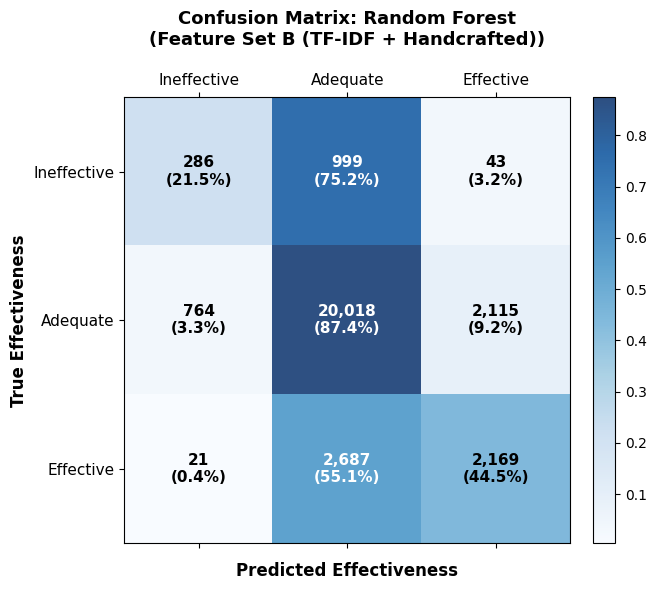

[SAVED] Confusion matrix figure exported to: /content/week9_person1_20261014/outputs/confusion_matrix_strongest_baseline.png


In [33]:
print("\n" + "=" * 80)
print("SECTION 3.5:EXPORTING STRONGEST BASELINE PREDICTIONS & CONFUSION MATRIX")
print("=" * 80)

best_preds, best_probs, best_classes = val_predictions_dict[best_key]

# Ensure probability array maps correctly to ORDERED_LABELS
class_to_idx = {c: i for i, c in enumerate(best_classes)}
prob_ineff = best_probs[:, class_to_idx["Ineffective"]]
prob_adeq = best_probs[:, class_to_idx["Adequate"]]
prob_eff = best_probs[:, class_to_idx["Effective"]]

# Assemble prediction dataframe
df_best_preds = pd.DataFrame({
    "essay_id": df_val_split["essay_id"].values,
    "discourse_id": df_val_split["discourse_id"].values,
    "discourse_type": df_val_split["discourse_type"].values,
    "discourse_effectiveness_true": y_val,
    "discourse_effectiveness_pred": best_preds,
    "prob_Ineffective": prob_ineff.round(4),
    "prob_Adequate": prob_adeq.round(4),
    "prob_Effective": prob_eff.round(4),
})

preds_csv_path = OUTPUT_DIR / "strongest_baseline_predictions.csv"
df_best_preds.to_csv(preds_csv_path, index=False)
print(f"[SAVED] Strongest baseline validation predictions exported to: {preds_csv_path.resolve()}")

# Classification report of the strongest baseline
print("\n--- CLASSIFICATION REPORT: STRONGEST CLASSICAL BASELINE ---")
print(classification_report(y_val, best_preds, labels=ORDERED_LABELS, target_names=ORDERED_LABELS, digits=4))

# Confusion Matrix Computation
cm_counts = confusion_matrix(y_val, best_preds, labels=ORDERED_LABELS)
cm_norm = confusion_matrix(y_val, best_preds, labels=ORDERED_LABELS, normalize="true")

df_cm_counts = pd.DataFrame(cm_counts, index=[f"True_{c}" for c in ORDERED_LABELS], columns=[f"Pred_{c}" for c in ORDERED_LABELS])
df_cm_norm = pd.DataFrame((cm_norm * 100).round(2), index=[f"True_{c}" for c in ORDERED_LABELS], columns=[f"Pred_{c} (%)" for c in ORDERED_LABELS])

print("\n--- CONFUSION MATRIX (COUNTS) ---")
print(df_cm_counts.to_string())

print("\n--- CONFUSION MATRIX (ROW-NORMALIZED PERCENTAGES %) ---")
print(df_cm_norm.to_string())

# Save confusion matrix CSV
cm_csv_path = OUTPUT_DIR / "confusion_matrix_strongest_baseline.csv"
df_cm_counts.to_csv(cm_csv_path)
print(f"[SAVED] Confusion matrix exported to: {cm_csv_path.resolve()}")

# Plot and save publication-grade Confusion Matrix Figure
fig, ax = plt.subplots(figsize=(7, 6))
cax = ax.matshow(cm_norm, cmap=plt.cm.Blues, alpha=0.85)

for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        count_val = cm_counts[i, j]
        pct_val = cm_norm[i, j] * 100
        text_color = "white" if cm_norm[i, j] > 0.5 else "black"
        ax.text(j, i, f"{count_val:,}\n({pct_val:.1f}%)", ha="center", va="center", color=text_color, fontsize=11, fontweight="bold")

fig.colorbar(cax, fraction=0.046, pad=0.04)
ax.set_xticks(range(len(ORDERED_LABELS)))
ax.set_yticks(range(len(ORDERED_LABELS)))
ax.set_xticklabels(ORDERED_LABELS, fontsize=11)
ax.set_yticklabels(ORDERED_LABELS, fontsize=11)
ax.set_xlabel("Predicted Effectiveness", fontsize=12, fontweight="bold", labelpad=10)
ax.set_ylabel("True Effectiveness", fontsize=12, fontweight="bold")
ax.set_title(f"Confusion Matrix: {best_model_name}\n({best_feature_set})", fontsize=13, fontweight="bold", pad=20)

plt.tight_layout()
cm_fig_path = OUTPUT_DIR / "confusion_matrix_strongest_baseline.png"
plt.savefig(cm_fig_path, dpi=300)
plt.show()
plt.close()
print(f"[SAVED] Confusion matrix figure exported to: {cm_fig_path.resolve()}")

## 4. Kiểm tra file bàn giao
Tên bảng tổng hợp theo **script gốc** là `classical_baselines_summary.csv`
(file hướng dẫn đang ghi `classical_summary.csv`). Không đổi tên CSV.

`strongest_baseline_predictions.csv` giữ nguyên các cột nhãn chuỗi
`discourse_effectiveness_true/pred` và `prob_Ineffective/Adequate/Effective`.
**Lưu ý khi bàn giao Người 2:** script 02 hiện đang đọc cột số `pred_label`,
nên phía nhận cần ánh xạ schema này trước khi so sánh. Notebook này không
thay đổi schema hoặc sửa script 02.

In [34]:
EXPECTED_ARTIFACTS = [
    "split_assignments.csv",
    "dataset_split_summary_table.csv",
    "lr_diagnostic_ablation_summary.csv",
    "classical_baselines_summary.csv",
    "strongest_baseline_predictions.csv",
    "confusion_matrix_strongest_baseline.csv",
    "eda_length_distributions_by_label.png",
    "confusion_matrix_strongest_baseline.png",
]
for filename in EXPECTED_ARTIFACTS:
    path = OUTPUT_DIR / filename
    assert path.is_file() and path.stat().st_size > 0, f"Thiếu output: {path}"
saved_split = pd.read_csv(OUTPUT_DIR / "split_assignments.csv", dtype={"essay_id": str})
saved_preds = pd.read_csv(OUTPUT_DIR / "strongest_baseline_predictions.csv", dtype={"essay_id": str, "discourse_id": str})
assert not saved_split["essay_id"].duplicated().any()
assert train_essays.isdisjoint(val_essays)
assert len(saved_preds) == len(df_val_split)
assert np.array_equal(saved_preds["discourse_effectiveness_true"].values, y_val)
assert np.array_equal(saved_preds["discourse_effectiveness_pred"].values, best_preds)
assert saved_preds["discourse_id"].tolist() == df_val_split["discourse_id"].astype(str).tolist()
if saved_preds["discourse_id"].duplicated().any():
    print("[WARNING] Dataset has duplicate discourse_id values; verify original IDs before Person 2 pairs predictions.")
assert set(saved_preds["essay_id"].astype(str)) == {str(x) for x in val_essays}
assert np.allclose(saved_preds.filter(like="prob_").sum(axis=1), 1.0, atol=2e-4)
display(pd.DataFrame([
    {"File": f"outputs/{name}", "Bytes": (OUTPUT_DIR / name).stat().st_size}
    for name in EXPECTED_ARTIFACTS
]))
print("[PASS] Đủ 6 CSV + 2 PNG; dự đoán đúng thứ tự validation; không trùng essay train/val.")

[WARNING] Dataset has duplicate discourse_id values; verify original IDs before Person 2 pairs predictions.


,File,Bytes
0,outputs/split_assignments.csv,382537
1,outputs/dataset_split_summary_table.csv,397
2,outputs/lr_diagnostic_ablation_summary.csv,665
3,outputs/classical_baselines_summary.csv,1147
4,outputs/strongest_baseline_predictions.csv,2437309
5,outputs/confusion_matrix_strongest_baseline.csv,132
6,outputs/eda_length_distributions_by_label.png,176080
7,outputs/confusion_matrix_strongest_baseline.png,197399


[PASS] Đủ 6 CSV + 2 PNG; dự đoán đúng thứ tự validation; không trùng essay train/val.


## 5. Tải toàn bộ kết quả
ZIP chứa nguyên thư mục `outputs/` với tên file gốc để gửi Người 2/3.
Trên Colab, cell này bắt đầu tải ZIP; có thể chạy lại cell để tải lần nữa.
Nếu dừng giữa chừng, có thể chạy riêng cell này để tải những file đã có,
nhưng chúng chưa phải bộ kết quả benchmark đầy đủ.

In [35]:
import shutil
from IPython.display import FileLink, display

archive_path = shutil.make_archive(
    "week9_person1_outputs", "zip",
    root_dir=str(OUTPUT_DIR.resolve().parent), base_dir=OUTPUT_DIR.name,
)
print(f"[SAVED] {archive_path}")
if IN_COLAB:
    from google.colab import files
    files.download(archive_path)
else:
    display(FileLink(Path(archive_path).name))

[SAVED] /content/week9_person1_20261014/week9_person1_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>